# Notebook 36 — Chronological thresholds and constrained portfolio simulation

**Question:** Does the OOF meta-logistic ranking advantage persist when entry thresholds are fixed using earlier calibration observations, with per-day position caps, turnover costs and optional sector exposure limits?

**Inputs:** Notebook 34 saved development-validation predictions and its training-period-calibrated policy thresholds. Notebook 35 retrospective top-k rankings are **not** used for trade selection.

**Scope:** Diagnostic next-bar equal-weight simulation, not a broker-ready backtest. Assumes complete one-bar positions and frictionless entry/exit except stated costs. Does not access the closed final holdout or prospective ledger.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
if not (ROOT/'src').exists():raise FileNotFoundError('Run inside stock_ml_dynamic repository')
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd,numpy as np,matplotlib.pyplot as plt
from IPython.display import display
from stock_ml_dynamic.deployable_policy_research import run_research,load_inputs
PRED=ROOT/'artifacts/notebook34_calibration_coverage/validation_predictions.parquet'
POLICIES=ROOT/'artifacts/notebook34_calibration_coverage/policies.csv'
OUTPUT=ROOT/'artifacts/deployable_policy/1d'
print('Predictions:',PRED,'exists:',PRED.exists())
print('Prior-calibration policies:',POLICIES,'exists:',POLICIES.exists())
if not PRED.exists() or not POLICIES.exists():
    raise FileNotFoundError('Run Notebook 34 first; check its OUTPUT path for predictions and policies.')

Predictions: /home/oem/Documents/github/stock_ml_dynamic/artifacts/notebook34_calibration_coverage/validation_predictions.parquet exists: True
Prior-calibration policies: /home/oem/Documents/github/stock_ml_dynamic/artifacts/notebook34_calibration_coverage/policies.csv exists: True


## 1. Verify fixed, earlier-period thresholds

Notebook 34 derives these thresholds from calibration observations preceding each outer validation fold. This notebook **does not** optimize them using validation labels, returns, or score quantiles. The three models are evaluated over the same validation days.

In [2]:
COVERAGE=.10
CALIBRATION='raw'
pred,thresholds=load_inputs(PRED,POLICIES,calibration=CALIBRATION,coverage=COVERAGE)
display(thresholds[['fold','model','target_coverage','threshold']].sort_values(['fold','model']))
print('Validation observations:',len(pred),'folds:',sorted(pred.fold.unique()))
print('Validation date range:',pred.bar_timestamp.min(),pred.bar_timestamp.max())

,fold,model,target_coverage,threshold
1,1,full_history_rf,0.1,0.520131
11,1,oof_meta_logistic,0.1,0.489703
21,1,oof_meta_rf,0.1,0.469731
31,2,full_history_rf,0.1,0.513248
41,2,oof_meta_logistic,0.1,0.478857
51,2,oof_meta_rf,0.1,0.471778
61,3,full_history_rf,0.1,0.469970
71,3,oof_meta_logistic,0.1,0.449067
81,3,oof_meta_rf,0.1,0.441347


Validation observations: 467502 folds: [np.int64(1), np.int64(2), np.int64(3)]
Validation date range: 2022-05-27 00:00:00+00:00 2025-04-08 00:00:00+00:00


## 2. Portfolio assumptions

- Select stocks only when their score exceeds the **fixed earlier-calibrated threshold**.
- Rank eligible names by current score; take at most **10 positions per date** (a cross-sectional cap, not a persistent simultaneous-position engine).
- Each position is held for **one next-bar interval**; capital is divided into 10 equal slots, with unused slots held as cash.
- Deduct **10 bps per selected position** plus a **5 bps new-name turnover proxy**. This does not model spread dynamics, market impact, fills, dividends, or financing.
- Optional sector cap requires an explicit complete, point-in-time `symbol,sector` CSV. Without one, sector constraints are **not** claimed.
- `COOLDOWN_DAYS=0` allows repeat symbols on consecutive dates. Increase for a deliberate cooldown sensitivity check.

In [3]:
MAX_POSITIONS=10
MAX_PER_SECTOR=None
SECTOR_CSV=None  # Set to an audited point-in-time CSV with columns symbol,sector before enabling a sector cap
COOLDOWN_DAYS=0
COST_BPS=10
TURNOVER_BPS=5
result=run_research(PRED,POLICIES,coverage=COVERAGE,calibration=CALIBRATION,
    max_positions=MAX_POSITIONS,max_per_sector=MAX_PER_SECTOR,sector_csv=SECTOR_CSV,
    cooldown_days=COOLDOWN_DAYS,cost_bps=COST_BPS,turnover_bps=TURNOVER_BPS,
    reps=1000,block_days=10,output_dir=OUTPUT)
scores=result['scores'];daily=result['daily'];trades=result['trades'];confidence=result['confidence']
display(scores.round(6))

,fold,model,days,entries,coverage,active_days,avg_invested_fraction,mean_net_per_trade,up_precision,mean_daily_net,total_compounded_net,max_drawdown,mean_daily_new_names
0,1,full_history_rf,238,708,0.013709,120,0.297479,-0.000416,0.480226,-0.000124,-0.055428,-0.180804,2.016807
1,1,oof_meta_logistic,238,671,0.012992,114,0.281933,-0.000610,0.488823,-0.000172,-0.066168,-0.206253,1.802521
2,1,oof_meta_rf,238,1753,0.033943,226,0.736555,0.000232,0.456931,0.000171,-0.035212,-0.397679,4.373950
3,2,full_history_rf,239,319,0.006151,85,0.133473,0.001832,0.467085,0.000245,0.058450,-0.033509,1.054393
4,2,oof_meta_logistic,239,0,0.000000,0,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000
5,2,oof_meta_rf,239,400,0.007713,133,0.167364,0.002580,0.487500,0.000432,0.103880,-0.060187,1.029289
6,3,full_history_rf,239,1946,0.037191,236,0.814226,-0.000721,0.461973,-0.000587,-0.161848,-0.381386,5.280335
7,3,oof_meta_logistic,239,2304,0.044032,238,0.964017,-0.000988,0.450955,-0.000952,-0.241604,-0.411540,4.824268
8,3,oof_meta_rf,239,2376,0.045409,239,0.994142,-0.000916,0.454966,-0.000911,-0.231523,-0.401023,6.117155


## 3. Fold-by-fold portfolio comparison

Report coverage **actually achieved**, average fraction of portfolio slots filled, daily equal-weight net return, compounded historical return, and drawdown. The compounding is a simplified next-bar illustration and should not be interpreted as executable performance.

,fold,model,days,entries,coverage,up_precision,avg_invested_fraction,mean_net_per_trade,mean_daily_net,total_compounded_net,max_drawdown,mean_daily_new_names
0,1,full_history_rf,238,708,0.013709,0.480226,0.297479,-0.000416,-0.000124,-0.055428,-0.180804,2.016807
1,1,oof_meta_logistic,238,671,0.012992,0.488823,0.281933,-0.000610,-0.000172,-0.066168,-0.206253,1.802521
2,1,oof_meta_rf,238,1753,0.033943,0.456931,0.736555,0.000232,0.000171,-0.035212,-0.397679,4.373950
3,2,full_history_rf,239,319,0.006151,0.467085,0.133473,0.001832,0.000245,0.058450,-0.033509,1.054393
4,2,oof_meta_logistic,239,0,0.000000,NaN,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
5,2,oof_meta_rf,239,400,0.007713,0.487500,0.167364,0.002580,0.000432,0.103880,-0.060187,1.029289
6,3,full_history_rf,239,1946,0.037191,0.461973,0.814226,-0.000721,-0.000587,-0.161848,-0.381386,5.280335
7,3,oof_meta_logistic,239,2304,0.044032,0.450955,0.964017,-0.000988,-0.000952,-0.241604,-0.411540,4.824268
8,3,oof_meta_rf,239,2376,0.045409,0.454966,0.994142,-0.000916,-0.000911,-0.231523,-0.401023,6.117155


,coverage,up_precision,avg_invested_fraction,mean_daily_net,max_drawdown
model,,,,,
full_history_rf,0.019017,0.469761,0.415059,-0.000155,-0.198566
oof_meta_logistic,0.019008,0.469889,0.415317,-0.000375,-0.205931
oof_meta_rf,0.029021,0.466466,0.632687,-0.000103,-0.286297


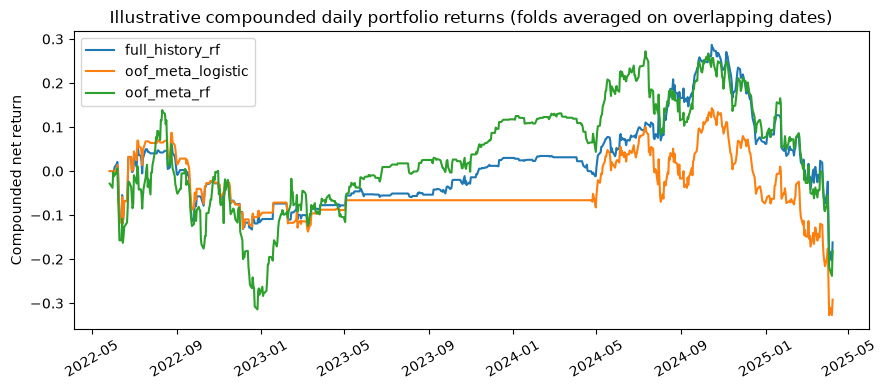

In [4]:
cols=['fold','model','days','entries','coverage','up_precision','avg_invested_fraction','mean_net_per_trade','mean_daily_net','total_compounded_net','max_drawdown','mean_daily_new_names']
display(scores[cols].sort_values(['fold','model']).round(6))
summary=scores.groupby('model')[['coverage','up_precision','avg_invested_fraction','mean_daily_net','max_drawdown']].mean()
display(summary.round(6))
fig,ax=plt.subplots(figsize=(9,4))
for model,g in daily.groupby('model'):
    bydate=g.groupby('bar_timestamp').net_portfolio_return.mean().sort_index()
    ax.plot(bydate.index,(1+bydate).cumprod()-1,label=model)
ax.set_title('Illustrative compounded daily portfolio returns (folds averaged on overlapping dates)')
ax.set_ylabel('Compounded net return');ax.legend();plt.xticks(rotation=30);plt.tight_layout();plt.show()

## 4. Paired uncertainty across market dates

Moving-block bootstrap (10-day blocks) of **paired daily portfolio return differences** for each chronological fold. These intervals describe historical sampling variability, not uncertainty from retraining models or live execution.

In [5]:
display(confidence.round(7))
print('Confidence intervals excluding zero:',int(((confidence.ci_low>0)|(confidence.ci_high<0)).sum()),'of',len(confidence))

,fold,challenger,days,mean_daily_net_difference,ci_low,ci_high,block_days,reps
0,1,oof_meta_logistic,238,-0.000048,-0.000434,0.000291,10,1000
1,2,oof_meta_logistic,239,-0.000244,-0.000636,0.000139,10,1000
2,3,oof_meta_logistic,239,-0.000365,-0.001454,0.000710,10,1000
3,1,oof_meta_rf,238,0.000294,-0.001927,0.002690,10,1000
4,2,oof_meta_rf,239,0.000187,-0.000375,0.000727,10,1000
5,3,oof_meta_rf,239,-0.000324,-0.001351,0.000813,10,1000


Confidence intervals excluding zero: 0 of 6


## 5. Threshold and capacity sensitivity

Coverage levels are **pre-specified** (5%, 10%, 15%, 20%, 25%) and their thresholds were already calibrated in Notebook 34. Evaluate 5 and 10 positions per day without selecting a winner based on this same validation set. Treat all comparisons as exploratory.

In [6]:
sensitivity=[]
for cov in [.05,.10,.15,.20,.25]:
    for cap in [5,10]:
        r=run_research(PRED,POLICIES,coverage=cov,calibration=CALIBRATION,
            max_positions=cap,cost_bps=COST_BPS,turnover_bps=TURNOVER_BPS,
            reps=20,block_days=10,output_dir=None)
        tab=r['scores'].copy();tab['target_coverage']=cov;tab['max_positions']=cap
        sensitivity.append(tab)
sensitivity=pd.concat(sensitivity,ignore_index=True)
display(sensitivity.groupby(['target_coverage','max_positions','model'])[['coverage','up_precision','mean_daily_net','avg_invested_fraction']].mean().round(6))
OUTPUT.mkdir(parents=True,exist_ok=True)
sensitivity.to_csv(OUTPUT/'sensitivity.csv',index=False)

coverage  up_precision  \
target_coverage max_positions model                                       
0.05            5             full_history_rf    0.006511      0.479768   
                              oof_meta_logistic  0.007923      0.502934   
                              oof_meta_rf        0.008012      0.424523   
                10            full_history_rf    0.009751      0.489448   
                              oof_meta_logistic  0.012660      0.489624   
                              oof_meta_rf        0.015659      0.423902   
0.10            5             full_history_rf    0.011196      0.474934   
                              oof_meta_logistic  0.010105      0.472269   
                              oof_meta_rf        0.016014      0.448533   
                10            full_history_rf    0.019017      0.469761   
                              oof_meta_logistic  0.019008      0.469889   
                              oof_meta_rf        0.029021      0.466466   
0.15            5             full_history_rf    0.014059      0.459478   
                              oof_meta_logistic  0.011466      0.475204   
                              oof_meta_rf        0.016897      0.449038   
                10            full_history_rf    0.024908      0.455888   
                              oof_meta_logistic  0.021455      0.469695   
                              oof_meta_rf        0.031123      0.466146   
0.20            5             full_history_rf    0.017445      0.461839   
                              oof_meta_logistic  0.013071      0.479906   
                              oof_meta_rf        0.017709      0.456213   
                10            full_history_rf    0.030218      0.460777   
                              oof_meta_logistic  0.024073      0.476174   
                              oof_meta_rf        0.033367      0.468254   
0.25            5             full_history_rf    0.020092      0.452746   
                              oof_meta_logistic  0.014708      0.463813   
                              oof_meta_rf        0.018686      0.458548   
                10            full_history_rf    0.035408      0.451779   
                              oof_meta_logistic  0.026987      0.460071   
                              oof_meta_rf        0.034788      0.470026   

                                                 mean_daily_net  \
target_coverage max_positions model                               
0.05            5             full_history_rf         -0.000326   
                              oof_meta_logistic       -0.000436   
                              oof_meta_rf             -0.000529   
                10            full_history_rf         -0.000035   
                              oof_meta_logistic       -0.000282   
                              oof_meta_rf             -0.000387   
0.10            5             full_history_rf         -0.000451   
                              oof_meta_logistic       -0.000766   
                              oof_meta_rf             -0.000171   
                10            full_history_rf         -0.000155   
                              oof_meta_logistic       -0.000375   
                              oof_meta_rf             -0.000103   
0.15            5             full_history_rf         -0.000320   
                              oof_meta_logistic       -0.000782   
                              oof_meta_rf             -0.000298   
                10            full_history_rf         -0.000223   
                              oof_meta_logistic       -0.000571   
                              oof_meta_rf             -0.000191   
0.20            5             full_history_rf         -0.000194   
                              oof_meta_logistic       -0.000526   
                              oof_meta_rf             -0.000211   
                10            full_history_rf         -0.000119   
                              oof_meta_l

## 6. Research interpretation and limitations

- Compare the **same fold/date pairs**, not just aggregate precision.
- Check whether a model's apparent edge persists after cash drag, capacity constraints, and churn costs.
- A score threshold calibrated on earlier data can still drift badly in later regimes; compare achieved coverage with target coverage.
- Sector exposure limits are **not implemented** unless an audited point-in-time sector map is supplied. Never substitute current sector membership for historical membership without disclosure.
- These are next-bar, daily grouped stock observations, not actual broker fills or an event-driven portfolio simulator. Overlapping return horizons and intra-day execution are not modeled.
- Do not tune the final strategy on the closed historical holdout. The prospective ledger is unchanged.

In [7]:
print('Notebook 36 outputs:',OUTPUT)
print('Saved daily portfolio returns, selected trades, confidence intervals and sensitivity tables.')
print('Closed final holdout and prospective ledger were not accessed.')

Notebook 36 outputs: /home/oem/Documents/github/stock_ml_dynamic/artifacts/deployable_policy/1d
Saved daily portfolio returns, selected trades, confidence intervals and sensitivity tables.
Closed final holdout and prospective ledger were not accessed.
